# Telco Customer Churn Prediction Using Machine Learning

## Programming in Python – Final-Term Project

### Project Type
Classification

### Problem Statement
Customer churn is an important challenge for telecommunication companies. This project aims to predict whether a customer is likely to churn using demographic, service, contract, tenure, and billing information.

### Objective
The objective is to develop, compare, and evaluate machine-learning classification models using a reproducible and leakage-safe data-science workflow.

### Target Variable
- Churn = Yes → Customer churned
- Churn = No → Customer did not churn

### Success Criteria
A useful model should outperform a simple baseline and provide reasonable precision, recall, F1-score, and ROC-AUC for identifying churn customers.

In [1]:
import os
import time
import json
import platform
import warnings
from pathlib import Path
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
 
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_validate
)
 
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
 
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
 
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
 
import sklearn
import joblib
 
warnings.filterwarnings("ignore")
 
print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
 
np.random.seed(RANDOM_STATE)
 
print("Random State:", RANDOM_STATE)
print("Test Size:", TEST_SIZE)
print("CV Folds:", CV_FOLDS)

Random State: 42
Test Size: 0.2
CV Folds: 5


In [3]:
CURRENT_DIR = Path.cwd()
 
if CURRENT_DIR.name.lower() == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR
 
DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
 
FIGURES_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
 
DATA_PATH = DATA_DIR / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
 
print("Current Directory:", CURRENT_DIR)
print("Project Root:", PROJECT_ROOT)
print("Dataset Path:", DATA_PATH)
print("Dataset Exists:", DATA_PATH.exists())

Current Directory: /Users/techemporium/Telco_Customer_Churn_Project/notebooks
Project Root: /Users/techemporium/Telco_Customer_Churn_Project
Dataset Path: /Users/techemporium/Telco_Customer_Churn_Project/data/WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset Exists: True


## 1. Data Provenance

The project uses a public Telco Customer Churn dataset containing customer demographic, subscription, service, contract, tenure, billing, and churn information.

The target variable is `Churn`, which indicates whether a customer left the telecommunications service.

The `customerID` field is treated as an identifier and is not used as a predictive feature.

### Privacy and Ethical Considerations

The dataset does not need customer identifiers for prediction. Model outputs represent statistical patterns rather than causal explanations. A real-world churn prediction system would require further fairness, privacy, business-cost, and population-shift assessment.

> The final report should cite the original dataset source and its usage/license information.

In [4]:
df_raw = pd.read_csv(DATA_PATH)
 
df = df_raw.copy()
 
print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
 
df.head()

Dataset loaded successfully.
Rows: 7043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Dataset Shape:")
print(df.shape)
 
print("\nColumn Names:")
print(df.columns.tolist())
 
print("\nData Types:")
print(df.dtypes)
 
print("\nDuplicate Rows:")
print(df.duplicated().sum())
 
print("\nDuplicate Customer IDs:")
print(df["customerID"].duplicated().sum())

Dataset Shape:
(7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Duplicate Rows:
0



In [6]:
print("Normal Missing Values:")
print(df.isnull().sum())
 
print("\nBlank String Check:")
 
for column in df.select_dtypes(include="object").columns:
    blank_count = (
        df[column]
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )
    if blank_count > 0:
        print(column, ":", blank_count)

Normal Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Blank String Check:
TotalCharges : 11


In [7]:
# Remove accidental leading/trailing spaces
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()
 
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)
 
print("TotalCharges data type:", df["TotalCharges"].dtype)
 
print(
    "Missing TotalCharges:",
    df["TotalCharges"].isnull().sum()
)

TotalCharges data type: float64
Missing TotalCharges: 11


In [8]:
print("Negative tenure:",
      (df["tenure"] < 0).sum())
 
print("Negative MonthlyCharges:",
      (df["MonthlyCharges"] < 0).sum())
 
print("Negative TotalCharges:",
      (df["TotalCharges"] < 0).sum())
 
print("Invalid SeniorCitizen:",
      (~df["SeniorCitizen"].isin([0, 1])).sum())
 
print("Invalid Churn labels:",
      (~df["Churn"].isin(["Yes", "No"])).sum())

Negative tenure: 0
Negative MonthlyCharges: 0
Negative TotalCharges: 0
Invalid SeniorCitizen: 0
Invalid Churn labels: 0


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


In [10]:
df.describe(include="object").T

,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


## 2. Exploratory Data Analysis

Exploratory analysis is used to examine class imbalance, important feature relationships, numerical distributions, and potential data-quality issues before modelling.

In [11]:
churn_summary = pd.DataFrame({
    "Count": df["Churn"].value_counts(),
    "Percentage": (
        df["Churn"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
})
 
churn_summary

,Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


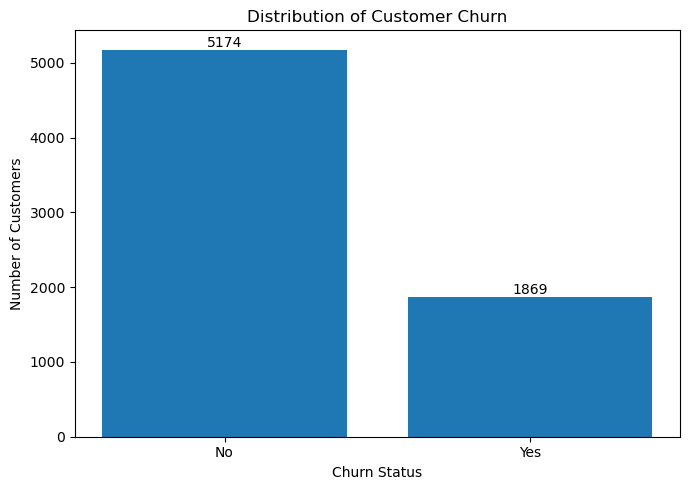

In [12]:
counts = df["Churn"].value_counts()
 
plt.figure(figsize=(7, 5))
 
bars = plt.bar(
    counts.index,
    counts.values
)
 
plt.title("Distribution of Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
 
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )
 
plt.tight_layout()
 
plt.savefig(
    FIGURES_DIR / "churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
 
plt.show()

In [13]:
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values()
)
 
contract_churn

Contract
Two year           2.831858
One year          11.269518
Month-to-month    42.709677
Name: Churn, dtype: float64

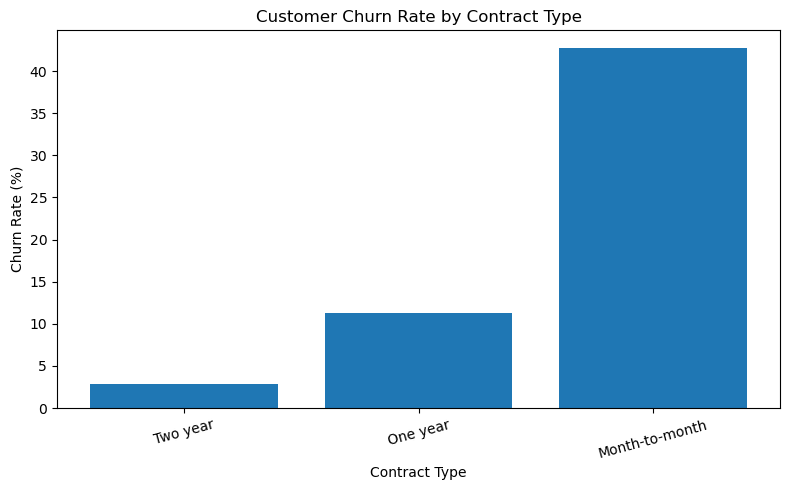

In [14]:
plt.figure(figsize=(8, 5))
 
plt.bar(
    contract_churn.index,
    contract_churn.values
)
 
plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
 
plt.xticks(rotation=15)
 
plt.tight_layout()
 
plt.savefig(
    FIGURES_DIR / "churn_by_contract.png",
    dpi=300,
    bbox_inches="tight"
)
 
plt.show()

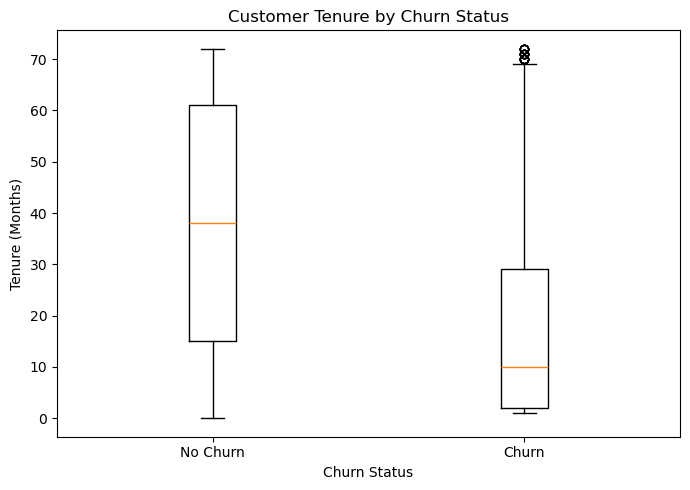

In [15]:
tenure_no = df.loc[

    df["Churn"] == "No",

    "tenure"

]
 
tenure_yes = df.loc[

    df["Churn"] == "Yes",

    "tenure"

]
 
plt.figure(figsize=(7, 5))
 
plt.boxplot(

    [tenure_no, tenure_yes],

    tick_labels=["No Churn", "Churn"]

)
 
plt.title("Customer Tenure by Churn Status")

plt.xlabel("Churn Status")

plt.ylabel("Tenure (Months)")
 
plt.tight_layout()
 
plt.savefig(

    FIGURES_DIR / "tenure_by_churn.png",

    dpi=300,

    bbox_inches="tight"

)
 
plt.show()
 

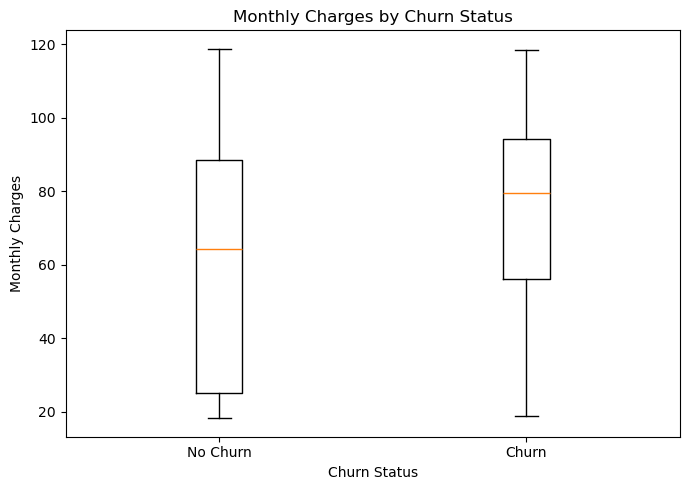

In [16]:
monthly_no = df.loc[

    df["Churn"] == "No",

    "MonthlyCharges"

]
 
monthly_yes = df.loc[

    df["Churn"] == "Yes",

    "MonthlyCharges"

]
 
plt.figure(figsize=(7, 5))
 
plt.boxplot(

    [monthly_no, monthly_yes],

    labels=["No Churn", "Churn"]

)
 
plt.title("Monthly Charges by Churn Status")

plt.xlabel("Churn Status")

plt.ylabel("Monthly Charges")
 
plt.tight_layout()
 
plt.savefig(

    FIGURES_DIR / "monthly_charges_by_churn.png",

    dpi=300,

    bbox_inches="tight"

)
 
plt.show()
 

## 3. Train-Test Split and Leakage Control

The dataset is split into training and testing sets before any data-dependent preprocessing is learned.

A stratified split is used because the churn classes are imbalanced.

The test set remains untouched during preprocessing, cross-validation, hyperparameter tuning, and model selection.

In [17]:
X = df.drop(
    columns=[
        "customerID",
        "Churn"
    ]
)
 
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})
 
print("X Shape:", X.shape)
print("y Shape:", y.shape)
 
print("\nTarget Distribution:")
print(y.value_counts())

X Shape: (7043, 19)
y Shape: (7043,)

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)
 
print("Training Rows:", X_train.shape[0])
print("Testing Rows:", X_test.shape[0])
 
print("\nTraining Churn Distribution:")
print(y_train.value_counts(normalize=True))
 
print("\nTesting Churn Distribution:")
print(y_test.value_counts(normalize=True))

Training Rows: 5634
Testing Rows: 1409

Training Churn Distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing Churn Distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [19]:
numeric_features = (
    X_train
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)
 
categorical_features = (
    X_train
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)
 
print("Numerical Features:")
print(numeric_features)
 
print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [20]:
numeric_pipeline = Pipeline(

    steps=[

        (

            "imputer",

            SimpleImputer(strategy="median")

        ),

        (

            "scaler",

            StandardScaler()

        )

    ]

)
 
categorical_pipeline = Pipeline(

    steps=[

        (

            "imputer",

            SimpleImputer(strategy="most_frequent")

        ),

        (

            "encoder",

            OneHotEncoder(

                handle_unknown="ignore"

            )

        )

    ]

)
 
preprocessor = ColumnTransformer(

    transformers=[

        (

            "numeric",

            numeric_pipeline,

            numeric_features

        ),

        (

            "categorical",

            categorical_pipeline,

            categorical_features

        )

    ]

)
 
print("Preprocessing pipeline created.")
 

Preprocessing pipeline created.


## 4. Baseline and Candidate Models

A Dummy Classifier is used as the baseline.

Three candidate machine-learning models are compared:

1. Logistic Regression
2. K-Nearest Neighbours
3. Random Forest

Model selection is performed using stratified cross-validation on the training data. F1-score is used as the primary selection metric because churn is the minority class.

In [21]:
cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)
 
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}
 
print("Cross-validation configured.")

Cross-validation configured.


In [22]:
baseline_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            DummyClassifier(
                strategy="most_frequent"
            )
        )
    ]
)
 
baseline_cv = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)
 
baseline_result = {
    "Model": "Dummy Classifier",
    "CV Accuracy": baseline_cv["test_accuracy"].mean(),
    "CV Precision": baseline_cv["test_precision"].mean(),
    "CV Recall": baseline_cv["test_recall"].mean(),
    "CV F1": baseline_cv["test_f1"].mean(),
    "CV ROC-AUC": baseline_cv["test_roc_auc"].mean()
}
 
pd.DataFrame([baseline_result]).round(4)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
0,Dummy Classifier,0.7346,0.0,0.0,0.0,0.5


In [23]:
models = {

    "Logistic Regression": {

        "model": LogisticRegression(

            max_iter=2000,

            random_state=RANDOM_STATE

        ),

        "params": {

            "model__C": [0.1, 1, 10],

            "model__class_weight": [None, "balanced"]

        }

    },


    "KNN": {

        "model": KNeighborsClassifier(),

        "params": {

            "model__n_neighbors": [5, 11, 21],

            "model__weights": ["uniform", "distance"]

        }

    },


    "Random Forest": {

        "model": RandomForestClassifier(

            random_state=RANDOM_STATE,

            n_jobs=-1

        ),

        "params": {

            "model__n_estimators": [100, 200],

            "model__max_depth": [None, 10],

            "model__min_samples_leaf": [1, 3],

            "model__class_weight": [None, "balanced"]

        }

    }

}
 
print("Candidate models created.")
 

Candidate models created.


In [24]:
model_results = []

best_models = {}
 
for model_name, config in models.items():

    print("\n" + "=" * 60)

    print("Training:", model_name)

    print("=" * 60)

    pipeline = Pipeline(

        steps=[

            (

                "preprocessor",

                preprocessor

            ),

            (

                "model",

                config["model"]

            )

        ]

    )

    grid = GridSearchCV(

        estimator=pipeline,

        param_grid=config["params"],

        scoring=scoring,

        refit="f1",

        cv=cv,

        n_jobs=-1,

        return_train_score=True

    )

    start_time = time.perf_counter()

    grid.fit(

        X_train,

        y_train

    )

    training_time = (

        time.perf_counter()

        - start_time

    )

    best_index = grid.best_index_

    model_results.append({

        "Model":

            model_name,

        "CV Accuracy":

            grid.cv_results_[

                "mean_test_accuracy"

            ][best_index],

        "CV Precision":

            grid.cv_results_[

                "mean_test_precision"

            ][best_index],

        "CV Recall":

            grid.cv_results_[

                "mean_test_recall"

            ][best_index],

        "CV F1":

            grid.cv_results_[

                "mean_test_f1"

            ][best_index],

        "CV F1 Std":

            grid.cv_results_[

                "std_test_f1"

            ][best_index],

        "CV ROC-AUC":

            grid.cv_results_[

                "mean_test_roc_auc"

            ][best_index],

        "Training Time":

            training_time,

        "Best Parameters":

            str(grid.best_params_)

    })

    best_models[

        model_name

    ] = grid.best_estimator_

    print("Best Parameters:")

    print(grid.best_params_)

    print(

        "Best CV F1:",

        round(grid.best_score_, 4)

    )
 


Training: Logistic Regression
Best Parameters:
{'model__C': 0.1, 'model__class_weight': 'balanced'}
Best CV F1: 0.6295

Training: KNN
Best Parameters:
{'model__n_neighbors': 21, 'model__weights': 'uniform'}
Best CV F1: 0.595

Training: Random Forest
Best Parameters:
{'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 3, 'model__n_estimators': 100}
Best CV F1: 0.6342


In [25]:
comparison_df = pd.DataFrame(
    model_results
)
 
comparison_df = (
    comparison_df
    .sort_values(
        by="CV F1",
        ascending=False
    )
    .reset_index(drop=True)
)
 
comparison_df.round(4)

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV F1 Std,CV ROC-AUC,Training Time,Best Parameters
0,Random Forest,0.7767,0.5613,0.7298,0.6342,0.0178,0.8439,8.4706,"{'model__class_weight': 'balanced', 'model__ma..."
1,Logistic Regression,0.7508,0.5199,0.7980,0.6295,0.0209,0.8455,1.4503,"{'model__C': 0.1, 'model__class_weight': 'bala..."
2,KNN,0.7906,0.6111,0.5799,0.5950,0.0136,0.8284,1.6542,"{'model__n_neighbors': 21, 'model__weights': '..."


In [26]:
baseline_df = pd.DataFrame([

    {

        "Model":

            baseline_result["Model"],

        "CV Accuracy":

            baseline_result["CV Accuracy"],

        "CV Precision":

            baseline_result["CV Precision"],

        "CV Recall":

            baseline_result["CV Recall"],

        "CV F1":

            baseline_result["CV F1"],

        "CV F1 Std":

            np.nan,

        "CV ROC-AUC":

            baseline_result["CV ROC-AUC"],

        "Training Time":

            np.nan,

        "Best Parameters":

            "Most Frequent Class"

    }

])
 
full_comparison = pd.concat(

    [

        baseline_df,

        comparison_df

    ],

    ignore_index=True

)
 
full_comparison.to_csv(

    RESULTS_DIR / "model_comparison.csv",

    index=False

)
 
full_comparison.round(4)
 

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV F1 Std,CV ROC-AUC,Training Time,Best Parameters
0,Dummy Classifier,0.7346,0.0000,0.0000,0.0000,NaN,0.5000,NaN,Most Frequent Class
1,Random Forest,0.7767,0.5613,0.7298,0.6342,0.0178,0.8439,8.4706,"{'model__class_weight': 'balanced', 'model__ma..."
2,Logistic Regression,0.7508,0.5199,0.7980,0.6295,0.0209,0.8455,1.4503,"{'model__C': 0.1, 'model__class_weight': 'bala..."
3,KNN,0.7906,0.6111,0.5799,0.5950,0.0136,0.8284,1.6542,"{'model__n_neighbors': 21, 'model__weights': '..."


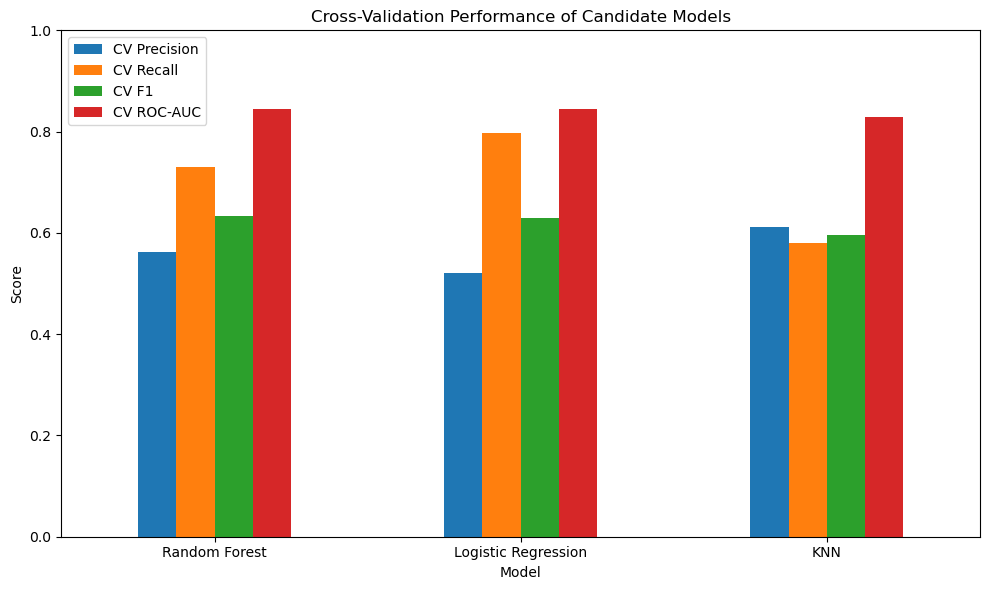

In [27]:
plot_df = comparison_df.set_index("Model")
 
plot_df[

    [

        "CV Precision",

        "CV Recall",

        "CV F1",

        "CV ROC-AUC"

    ]

].plot(

    kind="bar",

    figsize=(10, 6)

)
 
plt.title(

    "Cross-Validation Performance of Candidate Models"

)
 
plt.xlabel("Model")

plt.ylabel("Score")
 
plt.ylim(0, 1)
 
plt.xticks(rotation=0)
 
plt.tight_layout()
 
plt.savefig(

    FIGURES_DIR / "model_comparison.png",

    dpi=300,

    bbox_inches="tight"

)
 
plt.show()
 

In [28]:
selected_model_name = (
    comparison_df.iloc[0]["Model"]
)
 
final_model = best_models[
    selected_model_name
]
 
print(
    "Selected Final Model:",
    selected_model_name
)
 
print(
    "\nSelection Criterion: Highest Cross-Validation F1-score"
)

Selected Final Model: Random Forest

Selection Criterion: Highest Cross-Validation F1-score


## 5. Final Evaluation

After candidate models were compared using training-data cross-validation, the best model was selected using F1-score.

The selected model is now evaluated on the untouched test set. The test set was not used for preprocessing decisions, hyperparameter tuning, or model selection.

In [29]:
start_time = time.perf_counter()
 
y_pred = final_model.predict(
    X_test
)
 
y_probability = final_model.predict_proba(
    X_test
)[:, 1]
 
inference_time = (
    time.perf_counter()
    - start_time
)
 
print("Final predictions completed.")

Final predictions completed.


In [30]:
final_metrics = {

    "Model":

        selected_model_name,

    "Accuracy":

        accuracy_score(

            y_test,

            y_pred

        ),

    "Precision":

        precision_score(

            y_test,

            y_pred

        ),

    "Recall":

        recall_score(

            y_test,

            y_pred

        ),

    "F1":

        f1_score(

            y_test,

            y_pred

        ),

    "ROC-AUC":

        roc_auc_score(

            y_test,

            y_probability

        ),

    "PR-AUC":

        average_precision_score(

            y_test,

            y_probability

        ),

    "Inference Time":

        inference_time

}
 
final_metrics_df = pd.DataFrame(

    [final_metrics]

)
 
final_metrics_df.to_csv(

    RESULTS_DIR / "final_test_metrics.csv",

    index=False

)
 
final_metrics_df.round(4)
 

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Inference Time
0,Random Forest,0.7637,0.5406,0.7299,0.6212,0.8388,0.6431,0.0388


In [31]:
print(

    classification_report(

        y_test,

        y_pred,

        target_names=[

            "No Churn",

            "Churn"

        ]

    )

)
 

              precision    recall  f1-score   support

    No Churn       0.89      0.78      0.83      1035
       Churn       0.54      0.73      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.76      0.77      1409



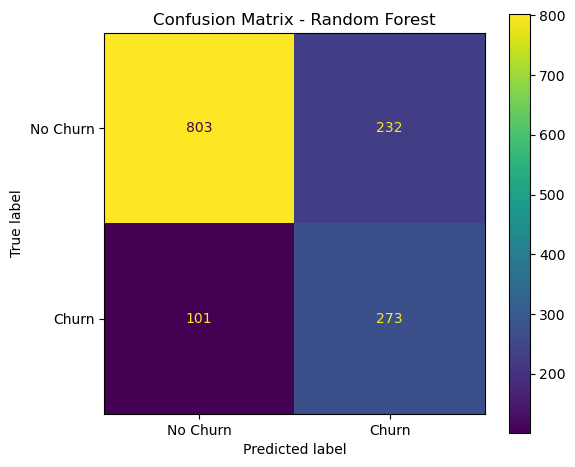

In [32]:
cm = confusion_matrix(

    y_test,

    y_pred

)
 
fig, ax = plt.subplots(

    figsize=(6, 5)

)
 
ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=[

        "No Churn",

        "Churn"

    ]

).plot(

    ax=ax,

    values_format="d"

)
 
plt.title(

    f"Confusion Matrix - {selected_model_name}"

)
 
plt.tight_layout()
 
plt.savefig(

    FIGURES_DIR / "confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)
 
plt.show()
 

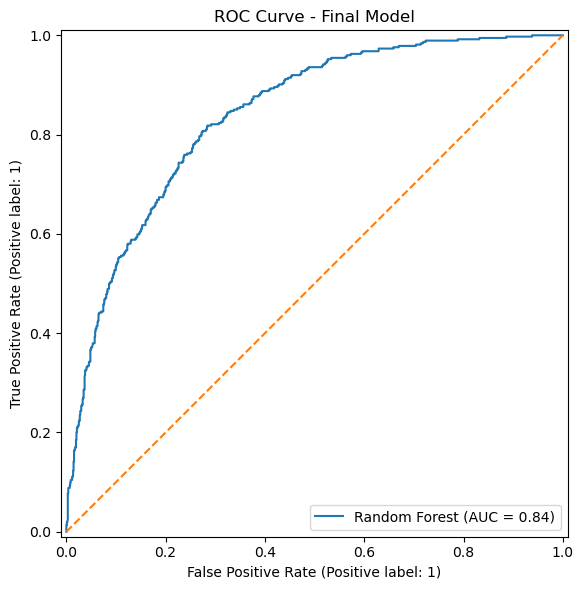

In [33]:
fig, ax = plt.subplots(

    figsize=(7, 6)

)
 
RocCurveDisplay.from_predictions(

    y_test,

    y_probability,

    name=selected_model_name,

    ax=ax

)
 
ax.plot(

    [0, 1],

    [0, 1],

    linestyle="--"

)
 
plt.title(

    "ROC Curve - Final Model"

)
 
plt.tight_layout()
 
plt.savefig(

    FIGURES_DIR / "roc_curve.png",

    dpi=300,

    bbox_inches="tight"

)
 
plt.show()
 

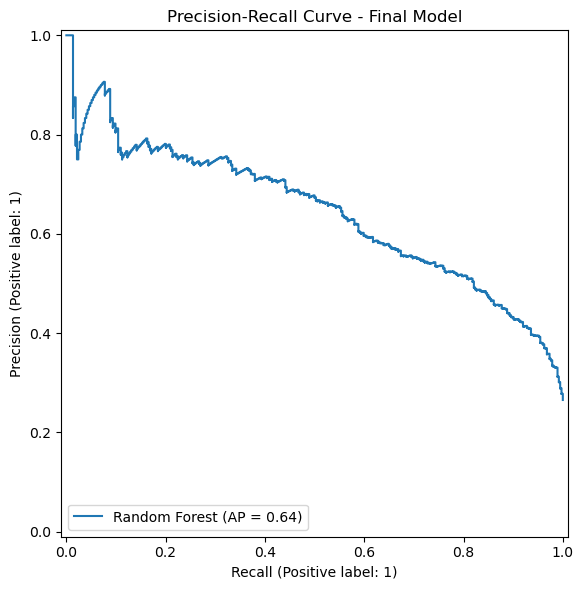

In [34]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)
 
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_probability,
    name=selected_model_name,
    ax=ax
)
 
plt.title(
    "Precision-Recall Curve - Final Model"
)
 
plt.tight_layout()
 
plt.savefig(
    FIGURES_DIR / "precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)
 
plt.show()

## 6. Error Analysis

False positives and false negatives are examined because overall accuracy alone does not explain the types of mistakes made by the classifier.

A false negative is particularly important in churn prediction because it represents a customer who actually churns but is predicted as a non-churn customer.

In [35]:
error_df = X_test.copy()
 
error_df["Actual_Churn"] = y_test.values

error_df["Predicted_Churn"] = y_pred

error_df["Churn_Probability"] = y_probability
 
false_positives = error_df[

    (error_df["Actual_Churn"] == 0) &

    (error_df["Predicted_Churn"] == 1)

]
 
false_negatives = error_df[

    (error_df["Actual_Churn"] == 1) &

    (error_df["Predicted_Churn"] == 0)

]
 
print(

    "False Positives:",

    len(false_positives)

)
 
print(

    "False Negatives:",

    len(false_negatives)

)
 
print(

    "Total Errors:",

    len(false_positives)

    +

    len(false_negatives)

)
 

False Positives: 232
False Negatives: 101
Total Errors: 333


In [36]:
false_negatives[

    [

        "tenure",

        "Contract",

        "InternetService",

        "MonthlyCharges",

        "TotalCharges",

        "Churn_Probability"

    ]

].head(10)
 

,tenure,Contract,InternetService,MonthlyCharges,TotalCharges,Churn_Probability
2488,31,Month-to-month,DSL,55.25,1715.65,0.187660
5086,45,One year,No,20.40,930.45,0.025046
7011,4,Month-to-month,DSL,60.40,272.15,0.335891
3158,18,Month-to-month,DSL,49.55,878.35,0.294360
5968,12,One year,DSL,74.05,872.65,0.251803
1577,17,One year,Fiber optic,98.60,1704.95,0.369466
1644,34,Month-to-month,Fiber optic,109.80,3587.25,0.447021
1014,18,Month-to-month,DSL,57.45,990.85,0.355261
6388,1,Month-to-month,No,20.40,20.40,0.491109
5207,24,Month-to-month,DSL,40.65,933.30,0.458568


In [37]:
false_positives.to_csv(
    RESULTS_DIR / "false_positives.csv",
    index=False
)
 
false_negatives.to_csv(
    RESULTS_DIR / "false_negatives.csv",
    index=False
)
 
print("Error-analysis files saved.")

Error-analysis files saved.


In [38]:
fitted_preprocessor = (

    final_model

    .named_steps["preprocessor"]

)
 
feature_names = (

    fitted_preprocessor

    .get_feature_names_out()

)
 
if selected_model_name == "Logistic Regression":

    coefficients = (

        final_model

        .named_steps["model"]

        .coef_[0]

    )

    feature_importance = pd.DataFrame({

        "Feature": feature_names,

        "Coefficient": coefficients,

        "Absolute_Coefficient":

            np.abs(coefficients)

    })

    feature_importance = (

        feature_importance

        .sort_values(

            "Absolute_Coefficient",

            ascending=False

        )

    )

    display(

        feature_importance.head(15)

    )
 
 
elif selected_model_name == "Random Forest":

    importances = (

        final_model

        .named_steps["model"]

        .feature_importances_

    )

    feature_importance = pd.DataFrame({

        "Feature": feature_names,

        "Importance": importances

    })

    feature_importance = (

        feature_importance

        .sort_values(

            "Importance",

            ascending=False

        )

    )

    display(

        feature_importance.head(15)

    )
 
 
else:

    print(

        "KNN does not provide direct "

        "model coefficients or standard "

        "feature importance."

    )
 

,Feature,Importance
1,numeric__tenure,0.118476
36,categorical__Contract_Month-to-month,0.111555
3,numeric__TotalCharges,0.102444
2,numeric__MonthlyCharges,0.072079
18,categorical__OnlineSecurity_No,0.067142
38,categorical__Contract_Two year,0.063845
16,categorical__InternetService_Fiber optic,0.048430
27,categorical__TechSupport_No,0.047631
43,categorical__PaymentMethod_Electronic check,0.042734
37,categorical__Contract_One year,0.018725


## 7. Assumptions, Bias, and Limitations

- The dataset is assumed to contain reasonably accurate customer information.
- The churn class is less common than the non-churn class, so accuracy alone is not sufficient.
- customerID was excluded because it is an identifier rather than a meaningful predictive feature.
- Missing TotalCharges values were imputed within the training pipeline to prevent data leakage.
- Model relationships should not be interpreted as causal explanations of customer churn.
- Customer behavior and market conditions may change over time, which could reduce future model performance.
- False negatives may cause a company to miss customers who are actually likely to churn.
- False positives may result in unnecessary retention efforts.
- A real-world system would require fairness analysis, business-specific threshold selection, monitoring, and periodic retraining.
- The model should support human decision-making rather than automatically determine customer treatment.

In [39]:
MODEL_PATH = (
    RESULTS_DIR /
    "final_model.joblib"
)
 
joblib.dump(
    final_model,
    MODEL_PATH
)
 
print(
    "Final model saved:",
    MODEL_PATH
)

Final model saved: /Users/techemporium/Telco_Customer_Churn_Project/results/final_model.joblib


In [40]:
environment_info = {
    "Python":
        platform.python_version(),
    "NumPy":
        np.__version__,
    "Pandas":
        pd.__version__,
    "Scikit-learn":
        sklearn.__version__,
    "Random State":
        RANDOM_STATE,
    "CV Folds":
        CV_FOLDS,
    "Test Size":
        TEST_SIZE
}
 
environment_info

{'Python': '3.13.5',
 'NumPy': '2.1.3',
 'Pandas': '2.2.3',
 'Scikit-learn': '1.6.1',
 'Random State': 42,
 'CV Folds': 5,
 'Test Size': 0.2}

In [41]:
with open(

    RESULTS_DIR / "environment_info.json",

    "w"

) as file:

    json.dump(

        environment_info,

        file,

        indent=4

    )
 
print(

    "Environment information saved."

)
 

Environment information saved.


In [42]:
requirements_text = f"""numpy=={np.__version__}

pandas=={pd.__version__}

matplotlib

scikit-learn=={sklearn.__version__}

joblib

jupyter

"""
 
with open(

    PROJECT_ROOT / "requirements.txt",

    "w"

) as file:

    file.write(

        requirements_text

    )
 
print(requirements_text)
 

numpy==2.1.3

pandas==2.2.3

matplotlib

scikit-learn==1.6.1

joblib

jupyter




## 8. Conclusion

This project implemented an end-to-end machine-learning workflow for predicting telecommunications customer churn.

A Dummy Classifier was used as a baseline, while Logistic Regression, K-Nearest Neighbours, and Random Forest were evaluated as candidate models. Preprocessing, including missing-value handling, feature scaling, and categorical encoding, was performed within machine-learning pipelines to prevent data leakage.

Candidate models were tuned and compared using stratified cross-validation on the training data. The final model was selected using cross-validation F1-score and was evaluated on the untouched test set using accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC, confusion matrix, and error analysis.

The model can provide useful decision-support information for identifying customers associated with higher churn risk. However, predictions should not be interpreted as causal explanations, and real-world use would require current organizational data, fairness assessment, appropriate business thresholds, and continuous performance monitoring.airness assessment, appropriate business thresholds, and continuous performance monitoring.


In [43]:
data_dictionary = pd.DataFrame([

    ["customerID", "Identifier", "Unique customer identifier"],

    ["gender", "Categorical", "Customer gender"],

    ["SeniorCitizen", "Binary Numeric", "Whether customer is a senior citizen: 1 = Yes, 0 = No"],

    ["Partner", "Categorical", "Whether customer has a partner"],

    ["Dependents", "Categorical", "Whether customer has dependents"],

    ["tenure", "Numeric", "Number of months the customer has stayed with the company"],

    ["PhoneService", "Categorical", "Whether customer has phone service"],

    ["MultipleLines", "Categorical", "Whether customer has multiple phone lines"],

    ["InternetService", "Categorical", "Type of internet service"],

    ["OnlineSecurity", "Categorical", "Whether customer has online security"],

    ["OnlineBackup", "Categorical", "Whether customer has online backup"],

    ["DeviceProtection", "Categorical", "Whether customer has device protection"],

    ["TechSupport", "Categorical", "Whether customer has technical support"],

    ["StreamingTV", "Categorical", "Whether customer uses streaming TV"],

    ["StreamingMovies", "Categorical", "Whether customer uses streaming movies"],

    ["Contract", "Categorical", "Customer contract type"],

    ["PaperlessBilling", "Categorical", "Whether paperless billing is used"],

    ["PaymentMethod", "Categorical", "Customer payment method"],

    ["MonthlyCharges", "Numeric", "Monthly amount charged to the customer"],

    ["TotalCharges", "Numeric", "Total amount charged to the customer"],

    ["Churn", "Target / Binary", "Whether customer churned: Yes or No"]

],

columns=["Variable", "Type", "Description"])
 
data_dictionary.to_csv(

    RESULTS_DIR / "data_dictionary.csv",

    index=False

)
 
data_dictionary
 

,Variable,Type,Description
0,customerID,Identifier,Unique customer identifier
1,gender,Categorical,Customer gender
2,SeniorCitizen,Binary Numeric,"Whether customer is a senior citizen: 1 = Yes,..."
3,Partner,Categorical,Whether customer has a partner
4,Dependents,Categorical,Whether customer has dependents
5,tenure,Numeric,Number of months the customer has stayed with ...
6,PhoneService,Categorical,Whether customer has phone service
7,MultipleLines,Categorical,Whether customer has multiple phone lines
8,InternetService,Categorical,Type of internet service
9,OnlineSecurity,Categorical,Whether customer has online security


In [44]:
classification_report_df = pd.DataFrame(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        output_dict=True
    )
).transpose()
 
classification_report_df.to_csv(
    RESULTS_DIR / "classification_report.csv"
)
 
classification_report_df.round(4)

,precision,recall,f1-score,support
No Churn,0.8883,0.7758,0.8283,1035.0000
Churn,0.5406,0.7299,0.6212,374.0000
accuracy,0.7637,0.7637,0.7637,0.7637
macro avg,0.7144,0.7529,0.7247,1409.0000
weighted avg,0.7960,0.7637,0.7733,1409.0000


In [45]:
if "feature_importance" in globals():
 
    feature_importance.to_csv(

        RESULTS_DIR / "feature_interpretation.csv",

        index=False

    )
 
    print("Feature interpretation saved.")
 
else:

    print(

        "No direct feature-importance table is available "

        "for the selected model."

    )
 

Feature interpretation saved.


In [46]:
readme_text = """# Telco Customer Churn Prediction Using Machine Learning
 
## Project Overview
 
This project develops an end-to-end machine-learning classification workflow for predicting telecommunications customer churn.
 
## Dataset Location
 
Place the dataset at:
 
data/WA_Fn-UseC_-Telco-Customer-Churn.csv
 
## Project Structure
 
Telco_Customer_Churn_Project/

    data/

    notebooks/

    figures/

    results/

    README.md

    requirements.txt
 
## Models
 
- Dummy Classifier (Baseline)

- Logistic Regression

- K-Nearest Neighbours

- Random Forest
 
## Workflow
 
1. Problem formulation

2. Data loading

3. Data audit and cleaning

4. Exploratory data analysis

5. Stratified train-test split

6. Leakage-safe preprocessing

7. Baseline evaluation

8. Candidate-model training

9. Cross-validation and hyperparameter tuning

10. Final model selection

11. Test-set evaluation

12. Error analysis

13. Model interpretation

14. Reproducibility documentation
 
## Reproducibility
 
Random State: 42

Test Size: 20%

Cross-validation: 5-fold Stratified Cross-Validation
 
## Running the Project
 
1. Install the required packages:
 
   pip install -r requirements.txt
 
2. Open:
 
   notebooks/Telco_Customer_Churn_Prediction.ipynb
 
3. Restart the Jupyter kernel.
 
4. Run all cells from top to bottom.
 
The notebook automatically generates figures and result files.

"""
 
with open(

    PROJECT_ROOT / "README.md",

    "w",

    encoding="utf-8"

) as file:

    file.write(readme_text)
 
print("README.md created successfully.")
 

README.md created successfully.


In [47]:
print("=" * 70)

print("FINAL PROJECT CHECK")

print("=" * 70)
 
print("\nDataset:")

print("Rows:", df.shape[0])

print("Columns:", df.shape[1])
 
print("\nTrain/Test:")

print("Training Rows:", X_train.shape[0])

print("Testing Rows:", X_test.shape[0])
 
print("\nSelected Model:")

print(selected_model_name)
 
print("\nFinal Test Metrics:")

print(final_metrics_df.round(4).to_string(index=False))
 
print("\nGenerated Figures:")

for file in FIGURES_DIR.iterdir():

    print("-", file.name)
 
print("\nGenerated Result Files:")

for file in RESULTS_DIR.iterdir():

    print("-", file.name)
 
print("\nREADME Exists:",

      (PROJECT_ROOT / "README.md").exists())
 
print("requirements.txt Exists:",

      (PROJECT_ROOT / "requirements.txt").exists())
 
print("\nPROJECT FINALIZATION CHECK COMPLETED")
 

FINAL PROJECT CHECK

Dataset:
Rows: 7043
Columns: 21

Train/Test:
Training Rows: 5634
Testing Rows: 1409

Selected Model:
Random Forest

Final Test Metrics:
        Model  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Inference Time
Random Forest    0.7637     0.5406  0.7299 0.6212   0.8388  0.6431          0.0388

Generated Figures:
- confusion_matrix.png
- monthly_charges_by_churn.png
- tenure_by_churn.png
- precision_recall_curve.png
- roc_curve.png
- churn_by_contract.png
- churn_distribution.png
- model_comparison.png

Generated Result Files:
- feature_interpretation.csv
- environment_info.json
- model_comparison.csv
- classification_report.csv
- final_test_metrics.csv
- false_negatives.csv
- false_positives.csv
- data_dictionary.csv
- final_model.joblib

README Exists: True
requirements.txt Exists: True

PROJECT FINALIZATION CHECK COMPLETED


In [48]:
print("Selected Model:", selected_model_name)
 
print("\nFinal Test Metrics")
print("------------------")
print("Accuracy:", round(final_metrics["Accuracy"], 4))
print("Precision:", round(final_metrics["Precision"], 4))
print("Recall:", round(final_metrics["Recall"], 4))
print("F1:", round(final_metrics["F1"], 4))
print("ROC-AUC:", round(final_metrics["ROC-AUC"], 4))
print("PR-AUC:", round(final_metrics["PR-AUC"], 4))
 
print("\nError Analysis")
print("--------------")
print("False Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))

Selected Model: Random Forest

Final Test Metrics
------------------
Accuracy: 0.7637
Precision: 0.5406
Recall: 0.7299
F1: 0.6212
ROC-AUC: 0.8388
PR-AUC: 0.6431

Error Analysis
--------------
False Positives: 232
False Negatives: 101


In [49]:
print("MODEL COMPARISON")
print("=" * 80)
 
display(
    full_comparison[
        [
            "Model",
            "CV Accuracy",
            "CV Precision",
            "CV Recall",
            "CV F1",
            "CV ROC-AUC",
            "Best Parameters"
        ]
    ].round(4)
)

MODEL COMPARISON


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,Best Parameters
0,Dummy Classifier,0.7346,0.0000,0.0000,0.0000,0.5000,Most Frequent Class
1,Random Forest,0.7767,0.5613,0.7298,0.6342,0.8439,"{'model__class_weight': 'balanced', 'model__ma..."
2,Logistic Regression,0.7508,0.5199,0.7980,0.6295,0.8455,"{'model__C': 0.1, 'model__class_weight': 'bala..."
3,KNN,0.7906,0.6111,0.5799,0.5950,0.8284,"{'model__n_neighbors': 21, 'model__weights': '..."


In [50]:
print("Random Forest Best Configuration")
print("=" * 50)
 
print(
    best_models["Random Forest"]
    .named_steps["model"]
)

Random Forest Best Configuration
RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=3, n_jobs=-1, random_state=42)


In [51]:
rf_model = best_models["Random Forest"].named_steps["model"]
 
print("n_estimators:", rf_model.n_estimators)
print("max_depth:", rf_model.max_depth)
print("min_samples_leaf:", rf_model.min_samples_leaf)
print("class_weight:", rf_model.class_weight)
print("random_state:", rf_model.random_state)

n_estimators: 100
max_depth: 10
min_samples_leaf: 3
class_weight: balanced
random_state: 42


In [52]:
rf_model = best_models["Random Forest"].named_steps["model"]
 
rf_preprocessor = best_models["Random Forest"].named_steps["preprocessor"]
 
feature_names = rf_preprocessor.get_feature_names_out()
 
rf_feature_importance = pd.DataFrame({

    "Feature": feature_names,

    "Importance": rf_model.feature_importances_

})
 
rf_feature_importance = (

    rf_feature_importance

    .sort_values(

        by="Importance",

        ascending=False

    )

    .reset_index(drop=True)

)
 
print("Top 10 Important Features")

print("=" * 60)
 
display(

    rf_feature_importance.head(10).round(4)

)
 

Top 10 Important Features


,Feature,Importance
0,numeric__tenure,0.1185
1,categorical__Contract_Month-to-month,0.1116
2,numeric__TotalCharges,0.1024
3,numeric__MonthlyCharges,0.0721
4,categorical__OnlineSecurity_No,0.0671
5,categorical__Contract_Two year,0.0638
6,categorical__InternetService_Fiber optic,0.0484
7,categorical__TechSupport_No,0.0476
8,categorical__PaymentMethod_Electronic check,0.0427
9,categorical__Contract_One year,0.0187


## Random Forest Feature Importance

The Random Forest feature-importance analysis showed that customer tenure was the most influential individual predictor, with an importance score of 0.1185. Month-to-month contract status was the second most important feature (0.1116), followed by TotalCharges (0.1024) and MonthlyCharges (0.0721).

Several service and contract-related variables also contributed substantially to the model, including absence of OnlineSecurity (0.0671), two-year contract status (0.0638), fiber-optic internet service (0.0484), absence of TechSupport (0.0476), and electronic-check payment (0.0427).

Notably, multiple encoded categories of the Contract variable appeared among the most important predictors, indicating that contract structure played an important role in the Random Forest's classification decisions.

The ten most important transformed features together accounted for approximately 69.3% of the total feature importance.

However, Random Forest feature importance measures the contribution of variables to prediction and does not indicate the direction of an association or establish causality. Therefore, these results should be interpreted as predictive importance rather than evidence that any feature directly causes customer churn.feature directly causes customer churn.
 

In [54]:
feature_group_importance = {}
 
for feature, importance in zip(

    feature_names,

    rf_model.feature_importances_

):

    clean_feature = feature.replace("numeric__", "").replace(

        "categorical__", ""

    )

    matched_feature = None

    for original_feature in X_train.columns:

        if (

            clean_feature == original_feature

            or clean_feature.startswith(original_feature + "_")

        ):

            matched_feature = original_feature

            break

    if matched_feature is not None:

        feature_group_importance[matched_feature] = (

            feature_group_importance.get(matched_feature, 0)

            + importance

        )
 
grouped_importance_df = pd.DataFrame(

    feature_group_importance.items(),

    columns=["Feature", "Importance"]

).sort_values(

    "Importance",

    ascending=False

).reset_index(drop=True)
 
display(grouped_importance_df.round(4))
 

,Feature,Importance
0,Contract,0.1941
1,tenure,0.1185
2,TotalCharges,0.1024
3,OnlineSecurity,0.0888
4,InternetService,0.0737
5,MonthlyCharges,0.0721
6,TechSupport,0.0705
7,PaymentMethod,0.0653
8,OnlineBackup,0.0334
9,StreamingMovies,0.0304


In [55]:
print(

    grouped_importance_df

    .round(4)

    .to_string(index=False)

)
 

         Feature  Importance
        Contract      0.1941
          tenure      0.1185
    TotalCharges      0.1024
  OnlineSecurity      0.0888
 InternetService      0.0737
  MonthlyCharges      0.0721
     TechSupport      0.0705
   PaymentMethod      0.0653
    OnlineBackup      0.0334
 StreamingMovies      0.0304
PaperlessBilling      0.0250
DeviceProtection      0.0222
     StreamingTV      0.0214
          gender      0.0189
   MultipleLines      0.0177
      Dependents      0.0170
         Partner      0.0157
   SeniorCitizen      0.0067
    PhoneService      0.0062


## Grouped Feature Importance Interpretation

The grouped Random Forest feature-importance analysis showed that Contract was the most influential original predictor, with an importance score of 0.1941. This was followed by tenure (0.1185), TotalCharges (0.1024), OnlineSecurity (0.0888), InternetService (0.0737), and MonthlyCharges (0.0721).

Together, these six features accounted for approximately 65.0% of the model's total feature importance. This indicates that the model relied strongly on contract structure, customer relationship duration, billing history, security-service status, internet-service type, and monthly charges when distinguishing between churn and non-churn customers.

Other influential predictors included TechSupport (0.0705) and PaymentMethod (0.0653). In contrast, variables such as SeniorCitizen (0.0067) and PhoneService (0.0062) contributed relatively little to the Random Forest's predictions.

The ten highest-ranked original features accounted for approximately 84.9% of the total feature importance.

However, Random Forest feature importance represents predictive contribution rather than the direction or causal effect of a variable. Therefore, a high importance score does not mean that a feature necessarily increases or decreases churn, nor does it establish that the feature causes customer churn.

In [57]:
grouped_importance_df.to_csv(
    RESULTS_DIR / "grouped_feature_importance.csv",
    index=False
)
 
print("Grouped feature importance saved successfully.")

Grouped feature importance saved successfully.


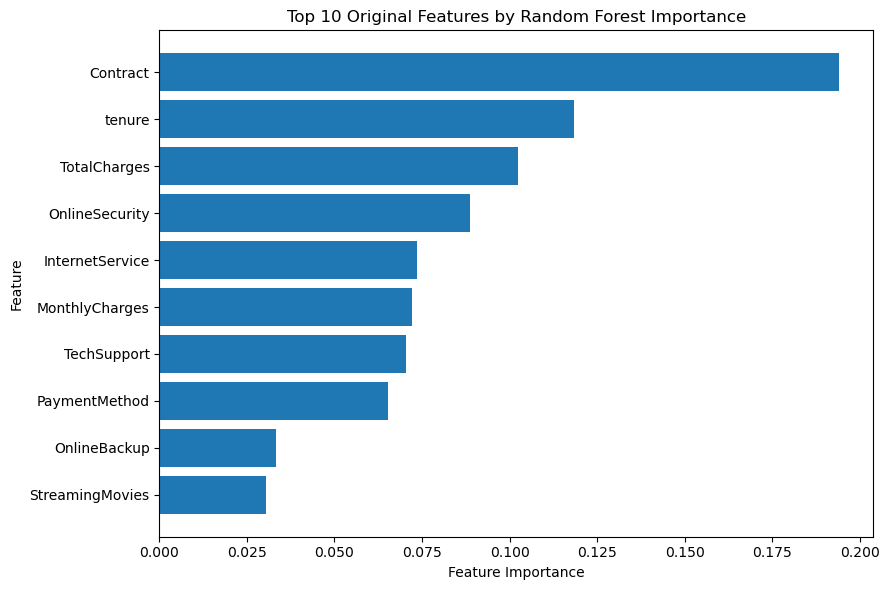

In [58]:
top_grouped_features = (

    grouped_importance_df

    .head(10)

    .sort_values(

        by="Importance",

        ascending=True

    )

)
 
plt.figure(figsize=(9, 6))
 
plt.barh(

    top_grouped_features["Feature"],

    top_grouped_features["Importance"]

)
 
plt.title("Top 10 Original Features by Random Forest Importance")

plt.xlabel("Feature Importance")

plt.ylabel("Feature")
 
plt.tight_layout()
 
plt.savefig(

    FIGURES_DIR / "grouped_feature_importance.png",

    dpi=300,

    bbox_inches="tight"

)
 
plt.show()
 

## Final Project Results
 
Random Forest was selected as the final model because it achieved the highest mean cross-validation F1-score (0.6342) among the candidate models. Logistic Regression achieved a very similar F1-score (0.6295), while K-Nearest Neighbours achieved 0.5950. Therefore, the Random Forest advantage was considered modest rather than substantial.
 
The selected Random Forest used 100 trees, a maximum depth of 10, a minimum of 3 samples per leaf, balanced class weighting, and a random state of 42.
 
On the untouched test set, the Random Forest achieved:
 
- Accuracy: 0.7637

- Precision: 0.5406

- Recall: 0.7299

- F1-score: 0.6212

- ROC-AUC: 0.8388

- PR-AUC: 0.6431
 
The model correctly identified 273 of the 374 customers who actually churned. However, it produced 232 false-positive predictions and 101 false-negative predictions.
 
The grouped feature-importance analysis identified Contract as the most influential original feature (0.1941), followed by tenure (0.1185), TotalCharges (0.1024), OnlineSecurity (0.0888), InternetService (0.0737), and MonthlyCharges (0.0721).
 
Overall, the model demonstrated useful churn-discrimination ability, particularly in identifying a substantial proportion of actual churn customers. Nevertheless, the relatively large number of false positives and the remaining false negatives indicate that the model should be used as a decision-support tool rather than an automatic decision-making system.
 


 

In [60]:
print("FIGURES")

print("=" * 50)
 
for file in sorted(FIGURES_DIR.iterdir()):

    print(file.name)
 
print("\nRESULTS")

print("=" * 50)
 
for file in sorted(RESULTS_DIR.iterdir()):

    print(file.name)
 

FIGURES
churn_by_contract.png
churn_distribution.png
confusion_matrix.png
grouped_feature_importance.png
model_comparison.png
monthly_charges_by_churn.png
precision_recall_curve.png
roc_curve.png
tenure_by_churn.png

RESULTS
classification_report.csv
data_dictionary.csv
environment_info.json
false_negatives.csv
false_positives.csv
feature_interpretation.csv
final_model.joblib
final_test_metrics.csv
grouped_feature_importance.csv
model_comparison.csv
